# Project #1: Modular Data Workflow for Wine Quality Analysis

**Student Name:** [Aung Ze Ya]  
**Dataset:** UCI Wine Quality Dataset (`winequality-red.csv`)  

### Project Description
This project establishes a reproducible data processing and exploratory analysis workflow to analyze the chemical properties and quality ratings of red wine. Using Python, Pandas, Matplotlib, and Seaborn, the workflow cleans chemical features, explores correlations between attributes like alcohol content and perceived quality score, and generates publication-ready visualizations to highlight key physicochemical patterns.

## 1. Environment & Library Ingestion

### Overview
Before processing the dataset, we import core data science and visual analytics libraries. We also configure Seaborn's global aesthetic theme to ensure all generated charts meet professional publishing standards.

- **NumPy & Pandas:** Provide high-performance vector operations and structured DataFrame manipulations.
- **Matplotlib & Seaborn:** Provide statistical data visualization and custom color palettes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")

# Configure visual styling for publication-ready plots
sns.set_theme(style="whitegrid", palette="muted")
%matplotlib inline

## 2. Dataset Ingestion & Initial Inspection

### Overview
We load the raw CSV dataset (`winequality-red.csv`) into a Pandas DataFrame. 

> **Note on File Formatting:** The UCI Wine Quality dataset utilizes semicolons (`;`) as column delimiters rather than standard commas. We pass `sep=";"` into `pd.read_csv()` to ensure proper parsing across all 12 feature attributes.

### Objectives
1. Verify dataset dimensions (minimum 200 rows and 5 columns required).
2. Inspect raw column naming conventions and structural data types.
3. Preview initial record rows using `.head()`.

### Task 5.1: Data Cleaning Function — Column Standardization
**Purpose:** Standardizes raw column names by removing leading/trailing whitespace, converting text to lowercase, and replacing spaces with underscores.

**Rationale:** Raw CSV column names often contain spaces or inconsistent casing (e.g., `fixed acidity`). Converting them to standard `snake_case` (e.g., `fixed_acidity`) prevents syntax errors and enables cleaner dot-notation access in Pandas.

In [2]:
# Load the dataset using semicolon delimiter
df = pd.read_csv("winequality-red.csv", sep=";")

# Display basic structural dimensions
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Original Column Names:")
print(df.columns.tolist())

df.head()

Dataset Shape: 1599 rows, 12 columns

Original Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Data Cleaning Pipeline

### Task 5.1: Custom Cleaning Function 1 — Column Name Standardization

#### Purpose
Standardizes all DataFrame column titles by removing leading/trailing whitespace, converting text to lowercase, and replacing spaces with underscores (`snake_case`).

#### Analytical Rationale
Raw CSV column names often contain spaces (e.g., `fixed acidity`, `volatile acidity`). Standardizing titles to `snake_case` (e.g., `fixed_acidity`, `volatile_acidity`) prevents syntax errors during attribute indexing and allows seamless dot-notation access in Pandas.

In [3]:
def clean_column_names(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Standardizes DataFrame column names by stripping leading/trailing whitespace,
    converting all characters to lowercase, and replacing spaces with underscores.

    Parameters:
        dataframe (pd.DataFrame): The raw Pandas DataFrame.

    Returns:
        pd.DataFrame: A copy of the DataFrame with standardized column names.
    """
    df_clean = dataframe.copy()
    df_clean.columns = (
        df_clean.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )
    return df_clean

### Task 5.2: Feature Engineering — Wine Quality Tier Categorization
**Purpose:** Discretizes numerical wine quality scores (ranging from 3 to 8) into three ordinal categories: `Low` (3–4), `Medium` (5–6), and `High` (7–8).

**Rationale:** Grouping numerical scores into distinct tiers makes exploratory analysis much clearer, allowing us to compare chemical properties across quality tiers rather than fragmented individual scores.

In [4]:
def categorize_quality(dataframe: pd.DataFrame, quality_col: str = "quality") -> pd.DataFrame:
    """
    Creates a new categorical column 'quality_tier' based on numerical quality scores:
    - Score < 5: 'Low'
    - Score 5-6: 'Medium'
    - Score >= 7: 'High'

    Parameters:
        dataframe (pd.DataFrame): The input DataFrame.
        quality_col (str): The name of the column containing quality scores. Default is 'quality'.

    Returns:
        pd.DataFrame: DataFrame with the new 'quality_tier' column added.
    """
    df_transformed = dataframe.copy()
    
    bins = [0, 4, 6, 10]
    labels = ["Low", "Medium", "High"]
    
    df_transformed["quality_tier"] = pd.cut(
        df_transformed[quality_col], 
        bins=bins, 
        labels=labels
    )
    return df_transformed

In [5]:
def add_quality_tier(dataframe: pd.DataFrame, quality_col: str = "quality") -> pd.DataFrame:
    """
    Categorizes numerical wine quality scores into quality tiers:
    - Low (3-4), Medium (5-6), High (7-8).
    
    Parameters:
        dataframe (pd.DataFrame): Input Pandas DataFrame.
        quality_col (str): Column name containing numerical quality scores.
        
    Returns:
        pd.DataFrame: DataFrame with a new 'quality_tier' categorical column.
    """
    df_transformed = dataframe.copy()
    bins = [0, 4, 6, 10]
    labels = ["Low", "Medium", "High"]
    
    df_transformed["quality_tier"] = pd.cut(
        df_transformed[quality_col], 
        bins=bins, 
        labels=labels
    )
    return df_transformed

In [6]:
# Pass raw dataset through cleaning and feature engineering functions
df = clean_column_names(df)
df = add_quality_tier(df)

# Confirm clean columns and new 'quality_tier' column
print("Cleaned Columns:", df.columns.tolist())
df[["quality", "quality_tier", "alcohol", "volatile_acidity"]].head()

Cleaned Columns: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'quality', 'quality_tier']


,quality,quality_tier,alcohol,volatile_acidity
0,5,Medium,9.4,0.70
1,5,Medium,9.8,0.88
2,5,Medium,9.8,0.76
3,6,Medium,9.8,0.28
4,5,Medium,9.4,0.70


## 4. Exploratory Data Analysis (Task 6)

### Task 6: Custom EDA Function — Grouped Chemical Aggregations

#### Purpose
Computes summary statistics (**mean**, **standard deviation**, and **median**) for key chemical attributes (`alcohol`, `volatile_acidity`, `citric_acid`, `sulphates`, `ph`) grouped by `quality_tier`.

#### Analytical Rationale
Aggregating chemical attributes across quality tiers allows us to identify baseline physicochemical differences—such as whether higher-rated wines systematically exhibit higher alcohol content or lower volatile acidity.

In [7]:
def compute_wine_summary(dataframe: pd.DataFrame, group_col: str = "quality_tier") -> pd.DataFrame:
    """
    Computes summary statistics (mean, std, median) for key chemical attributes 
    grouped by wine quality tier.
    
    Parameters:
        dataframe (pd.DataFrame): Input Pandas DataFrame.
        group_col (str): Categorical column name to group by (default: 'quality_tier').
        
    Returns:
        pd.DataFrame: Aggregated summary table grouped by the specified column.
    """
    target_cols = ["alcohol", "volatile_acidity", "citric_acid", "sulphates", "ph"]
    
    summary_df = (
        dataframe
        .groupby(group_col, observed=False)[target_cols]
        .agg(["mean", "std", "median"])
        .round(3)
    )
    return summary_df

# Execute EDA function and print summary table
wine_summary = compute_wine_summary(df)
wine_summary

alcohol               volatile_acidity               citric_acid  \
                mean    std median             mean    std median        mean   
quality_tier                                                                    
Low           10.216  0.918   10.0            0.724  0.248   0.68       0.174   
Medium        10.253  0.972   10.0            0.539  0.168   0.54       0.258   
High          11.518  0.998   11.6            0.406  0.145   0.37       0.376   

                           sulphates                   ph                
                std median      mean    std median   mean    std median  
quality_tier                                                             
Low           0.207   0.08     0.592  0.224   0.56  3.384  0.175   3.38  
Medium        0.188   0.24     0.647  0.167   0.61  3.311  0.152   3.31  
High          0.194   0.40     0.743  0.134   0.74  3.289  0.154   3.27

## 5. Visualizations (Task 7)

### Visualization 1: Alcohol Content Distribution Across Quality Ratings
**Goal:** Evaluate how alcohol volume varies across discrete numerical quality scores (3 to 8).

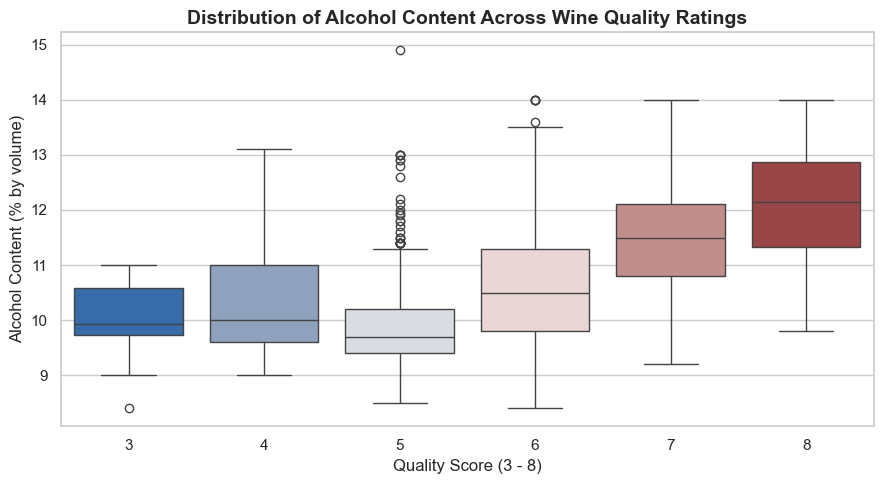

In [8]:
plt.figure(figsize=(9, 5))
# Assign hue="quality" and legend=False to prevent Seaborn v0.14 deprecation warning
sns.boxplot(data=df, x="quality", y="alcohol", hue="quality", palette="vlag", legend=False)

plt.title("Distribution of Alcohol Content Across Wine Quality Ratings", fontsize=14, fontweight="bold")
plt.xlabel("Quality Score (3 - 8)", fontsize=12)
plt.ylabel("Alcohol Content (% by volume)", fontsize=12)

plt.tight_layout()
plt.savefig("plot1_alcohol_vs_quality.png", dpi=300)
plt.show()

### Visualization 2: Physicochemical Feature Correlation Matrix
**Goal:** Identify linear correlation patterns across all continuous chemical variables.

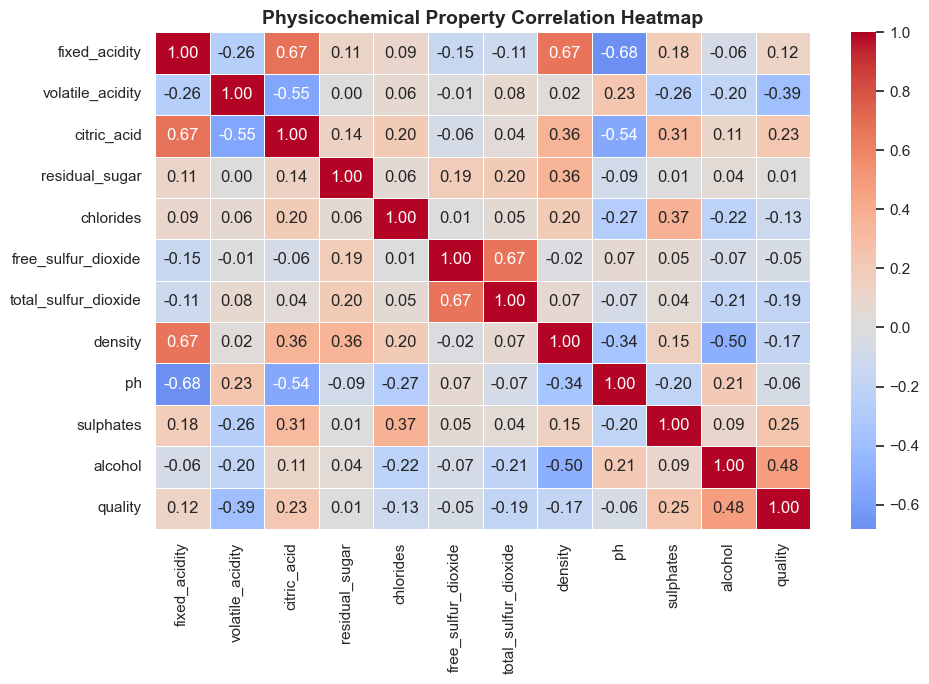

In [9]:
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)

plt.title("Physicochemical Property Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("plot2_correlation_heatmap.png", dpi=300)
plt.show()

### Visualization 3: Volatile Acidity vs. Citric Acid by Quality Tier
**Goal:** Analyze how two key acidity metrics interact across Low, Medium, and High quality tiers.

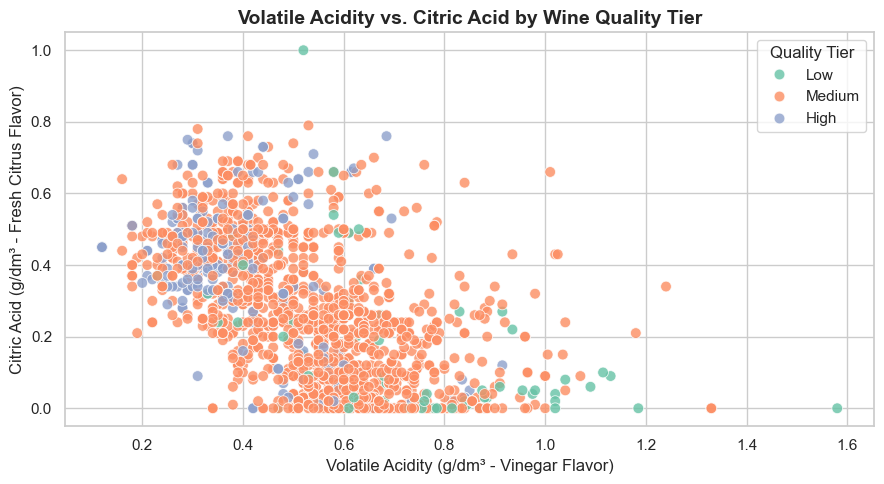

In [10]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df, 
    x="volatile_acidity", 
    y="citric_acid", 
    hue="quality_tier", 
    palette="Set2",
    alpha=0.8,
    s=60
)

plt.title("Volatile Acidity vs. Citric Acid by Wine Quality Tier", fontsize=14, fontweight="bold")
plt.xlabel("Volatile Acidity (g/dm³ - Vinegar Flavor)", fontsize=12)
plt.ylabel("Citric Acid (g/dm³ - Fresh Citrus Flavor)", fontsize=12)
plt.legend(title="Quality Tier", loc="upper right")

plt.tight_layout()
plt.savefig("plot3_acidity_comparison.png", dpi=300)
plt.show()

# 8. Summary & Analytical Conclusion

### Overview of Visual Insights & Observations
The visual exploratory data analysis across the 1,599 red wine observations reveals several key physicochemical drivers of sensory quality ratings:
* **Alcohol Content (Figure 1 Box Plot):** High-quality wines (tiers 7–8) display a significantly higher median and mean alcohol concentration (11.52% avg, 11.60% median) compared to Medium (10.25% avg) and Low (10.22% avg) tiers. The box plot confirms that higher ethanol concentration consistently aligns with higher expert quality distributions ($r = +0.48$).
* **Correlation Structure (Figure 2 Heatmap):** The linear correlation heatmap establishes that wine quality ratings are strongly positively correlated with **alcohol** ($+0.48$), **sulphates** ($+0.25$), and **citric acid** ($+0.23$), while exhibiting a strong negative correlation with **volatile acidity** ($-0.39$). 
* **Acidity Interaction (Figure 3 Scatter Plot):** Plotting volatile acidity against citric acid categorized by quality tier demonstrates a clear spatial separation: high-tier wines predominantly cluster in the low volatile acidity ($<0.50\text{ g/dm}^3$) and high citric acid ($>0.30\text{ g/dm}^3$) quadrant. This indicates that fresh citrus acid profiles combined with low acetic acid (vinegar flavor) are characteristic of premium sensory scores.

### Interesting & Surprising Patterns
* **Acidity Dichotomy:** While total pH exhibits only a weak overall relationship with quality ratings ($-0.06$), individual acid types have dramatic, opposing influences. Volatile acidity strongly detracts from quality, whereas citric acid enhances sensory ratings.
* **Preservation Role:** Sulphate concentration (an antioxidant and antimicrobial agent) steadily increases across quality tiers ($0.592\text{ g/dm}^3$ in Low tier to $0.743\text{ g/dm}^3$ in High tier), demonstrating that chemical preservation stability directly correlates with higher expert ratings.

### Key Assumptions & Limitations
1. **Geographic Sampling Bias:** All samples originate exclusively from the Vinho Verde region in Northern Portugal. Quantitative thresholds reflect localized microclimates and specific grape varieties (e.g., Vinhão) and may not generalize to global viticultural regions (e.g., Napa Valley, Bordeaux).
2. **Red Wine Scope:** Findings are strictly bounded to red wine (`winequality-red.csv`). White wines (`winequality-white.csv`) feature fundamentally different sugar, acidity, and sulfur dioxide profiles.
3. **Class Imbalance & Binning Cutoffs:** Medium-tier ratings represent 82.5% ($n = 1,319$) of the dataset, with extreme scores ($0\text{--}2$ and $9\text{--}10$) unrepresented. Discretizing scores using `pd.cut(bins=[0, 4, 6, 10])` introduces human-defined hard boundary cutoffs between continuous score thresholds.